# Driver Risk Analysis — reproducible Python version

This notebook reproduces the Hive/Pig pipeline from `sql/` and `pig/` in pandas so anyone can
re-run the analysis without a Hadoop cluster. Every step maps to a Hive table in the original pipeline.

**Inputs** (`data/`): `geolocation.csv` (8,000 telematics events), `trucks.csv` (100 trucks × 54 months of
miles and gas), `trucks_mg.csv` (mileage/gas summary).

In [1]:
import pandas as pd, numpy as np
from scipy import stats
import matplotlib.pyplot as plt

geo    = pd.read_csv('../data/geolocation.csv')
trucks = pd.read_csv('../data/trucks.csv')
print(geo.shape, trucks.shape)
geo['event'].value_counts()

(8000, 10) (100, 111)


event
normal                       7543
lane departure                152
unsafe following distance     150
overspeed                      90
unsafe tail distance           65
Name: count, dtype: int64

## Step 1 — `truck_mileage`: unpivot 54 monthly columns into rows (Hive `LATERAL VIEW STACK`)

In [2]:
months = [c[:-6] for c in trucks.columns if c.endswith('_miles')]
truck_mileage = pd.concat([
    pd.DataFrame({'truckid': trucks.truckid, 'driverid': trucks.driverid, 'rdate': m,
                  'miles': trucks[f'{m}_miles'], 'gas': trucks[f'{m}_gas']}) for m in months])
truck_mileage['mpg'] = truck_mileage.miles / truck_mileage.gas
print(len(truck_mileage), 'rows  (Hive: numRows=5400)')
truck_mileage.head()

5400 rows  (Hive: numRows=5400)


,truckid,driverid,rdate,miles,gas,mpg
0,A1,A1,jun13,9217,1914,4.815569
1,A2,A2,jun13,12058,2335,5.164026
2,A3,A3,jun13,13652,2899,4.709210
3,A4,A4,jun13,12687,2439,5.201722
4,A5,A5,jun13,10233,1825,5.607123


## Step 2 — `avg_mileage` and `drivermileage`

In [3]:
avg_mileage   = truck_mileage.groupby('truckid', as_index=False).mpg.mean().rename(columns={'mpg': 'avgmpg'})
drivermileage = truck_mileage.groupby('driverid', as_index=False).miles.sum().rename(columns={'miles': 'totmiles'})
avg_mileage.describe().round(2)

,avgmpg
count,100.00
mean,5.11
std,0.49
min,4.25
25%,4.75
50%,5.02
75%,5.49
max,6.30


## Step 3 — `riskfactor` (the Pig script)
Risk factor = unsafe (non-`normal`) events per million miles driven.

In [4]:
events = (geo[geo.event != 'normal'].groupby('driverid').size().rename('events').reset_index())
riskfactor = events.merge(drivermileage, on='driverid')
riskfactor['riskfactor'] = riskfactor.events / riskfactor.totmiles * 1_000_000
riskfactor = riskfactor.sort_values('riskfactor', ascending=False).reset_index(drop=True)
print('drivers with at least one unsafe event:', len(riskfactor))
riskfactor.head(10).round(2)

drivers with at least one unsafe event: 99


,driverid,events,totmiles,riskfactor
0,A97,20,631199,31.69
1,A73,10,642222,15.57
2,A35,9,637069,14.13
3,A50,9,640069,14.06
4,A5,9,676574,13.30
5,A95,8,642920,12.44
6,A71,8,672026,11.90
7,A92,7,618049,11.33
8,A86,7,629558,11.12
9,A44,7,652599,10.73


## Step 4 — `high_risk_drivers` (risk factor ≥ 7.0, the course threshold)

In [5]:
high_risk = riskfactor[riskfactor.riskfactor >= 7.0]
print(f'{len(high_risk)} of {len(riskfactor)} drivers are at or above the 7.0 threshold')
print('Top 10:', ', '.join(high_risk.driverid.head(10)))

53 of 99 drivers are at or above the 7.0 threshold
Top 10: A97, A73, A35, A50, A5, A95, A71, A92, A86, A44


## Step 5 — Enhanced Total Risk Score (ETRS) and risk categories
My extension of the course method: combine the risk factor with event frequency, speed and idling.

`ETRS = 0.5·(riskfactor/10) + 0.3·(events/max_events) + 0.1·(avg_velocity/max_velocity) + 0.1·(total_idling/max_idling)`

Categories: **Critical** ≥ 0.85 · **High** ≥ 0.65 · **Medium** ≥ 0.40 · **Low** below that.

In [6]:
behavior = (geo.groupby('driverid').agg(avg_velocity=('velocity', 'mean'), total_idling=('idling_ind', 'sum'))
            .reset_index())
d = riskfactor.merge(behavior, on='driverid')   # inner join, as in Hive
m = d[['events', 'avg_velocity', 'total_idling']].max()
d['etrs'] = (0.5 * d.riskfactor / 10 + 0.3 * d.events / m.events
             + 0.1 * d.avg_velocity / m.avg_velocity + 0.1 * d.total_idling / m.total_idling)
d['risk_category'] = np.select([(d.etrs >= 0.85) | (d.events >= 200), d.etrs >= 0.65, d.etrs >= 0.40],
                               ['Critical', 'High', 'Medium'], 'Low')
order = ['Critical', 'High', 'Medium', 'Low']
print(d.risk_category.value_counts().reindex(order, fill_value=0))
d.sort_values('etrs', ascending=False).head(10).round(3)

risk_category
Critical     7
High        25
Medium      47
Low         20
Name: count, dtype: int64


,driverid,events,totmiles,riskfactor,avg_velocity,total_idling,etrs,risk_category
0,A97,20,631199,31.686,37.612,19,2.045,Critical
1,A73,10,642222,15.571,38.862,15,1.078,Critical
2,A35,9,637069,14.127,30.212,26,1.009,Critical
3,A50,9,640069,14.061,36.538,14,0.978,Critical
4,A5,9,676574,13.302,34.350,20,0.956,Critical
5,A95,8,642920,12.443,32.325,23,0.904,Critical
6,A71,8,672026,11.904,33.162,24,0.883,Critical
7,A92,7,618049,11.326,38.512,13,0.813,High
8,A86,7,629558,11.119,34.838,18,0.811,High
9,A44,7,652599,10.726,31.088,19,0.786,High


## Step 6 — Correlation: which behaviour drives risk?

In [7]:
corr = d[['events', 'totmiles', 'avg_velocity', 'total_idling', 'riskfactor']].corr().round(3)
corr

,events,totmiles,avg_velocity,total_idling,riskfactor
events,1.000,-0.043,0.084,0.105,0.999
totmiles,-0.043,1.000,-0.042,0.108,-0.085
avg_velocity,0.084,-0.042,1.000,-0.707,0.087
total_idling,0.105,0.108,-0.707,1.000,0.099
riskfactor,0.999,-0.085,0.087,0.099,1.000


## Step 7 — ANOVA across risk categories

In [8]:
groups = [g for _, g in d.groupby('risk_category') if len(g) > 1]   # ANOVA needs ≥2 per group
for col in ['events', 'avg_velocity', 'total_idling']:
    f, p = stats.f_oneway(*[g[col] for g in groups])
    print(f'{col:13s}  F = {f:7.2f}   p = {p:.4g}')

events         F =  102.19   p = 1.259e-29
avg_velocity   F =    0.17   p = 0.9176
total_idling   F =    1.20   p = 0.3136


## Step 8 — Do cities influence risk? (Kruskal–Wallis, non-parametric)

In [9]:
# Original analysis method: each unsafe event carries its driver's risk factor, grouped by the city it happened in
ev = geo[geo.event != 'normal'][['driverid', 'city']].merge(riskfactor[['driverid', 'riskfactor']], on='driverid')
h, p = stats.kruskal(*[g.riskfactor for _, g in ev.groupby('city')])
print(f'Unsafe-event level: {ev.city.nunique()} cities   H = {h:.2f}   p = {p:.4f}')

# Robustness check: count each driver once per city instead of once per event
dc = geo[['driverid', 'city']].drop_duplicates().merge(riskfactor[['driverid', 'riskfactor']], on='driverid')
h2, p2 = stats.kruskal(*[g.riskfactor for _, g in dc.groupby('city')])
print(f'Driver-city level:  {dc.city.nunique()} cities   H = {h2:.2f}   p = {p2:.4f}')

Unsafe-event level: 54 cities   H = 75.62   p = 0.0224
Driver-city level:  54 cities   H = 31.88   p = 0.9905


**Reading this result:** at the unsafe-event level the test is significant (p ≈ 0.022), which matches the
original analysis. Unsafe events from the same driver are not independent, though, and when each driver is counted
once per city the difference disappears. So city effects are a lead worth investigating, not a settled finding.

## Step 9 — Data-quality check: why the class run produced inflated numbers
In the original Hive run, `trucks_mg.csv` was accidentally loaded into the **`geolocation`** table
(screenshot `08`), and the Pig job then read 16,103 records instead of 8,000 (screenshot `10`).
Every `trucks_mg` row has a date in the `event` column, so it counted as one extra "unsafe event"
per driver, and the duplicated read doubled the real ones — giving `events = 2 × real + 1`.

In [10]:
class_run = pd.read_csv('../analysis/class_run_riskfactor.csv')
check = class_run.merge(riskfactor[['driverid', 'events']], on='driverid', suffixes=('_class_run', '_corrected'))
check['matches_2x_plus_1'] = check.events_class_run == 2 * check.events_corrected + 1
print('rows following the 2x+1 pattern:', check.matches_2x_plus_1.sum(), 'of', len(check))
print('drivers >= 7.0 in class run:', (class_run.riskfactor >= 7).sum(), '| corrected:', len(high_risk))

rows following the 2x+1 pattern: 99 of 99
drivers >= 7.0 in class run: 92 | corrected: 53


## Charts

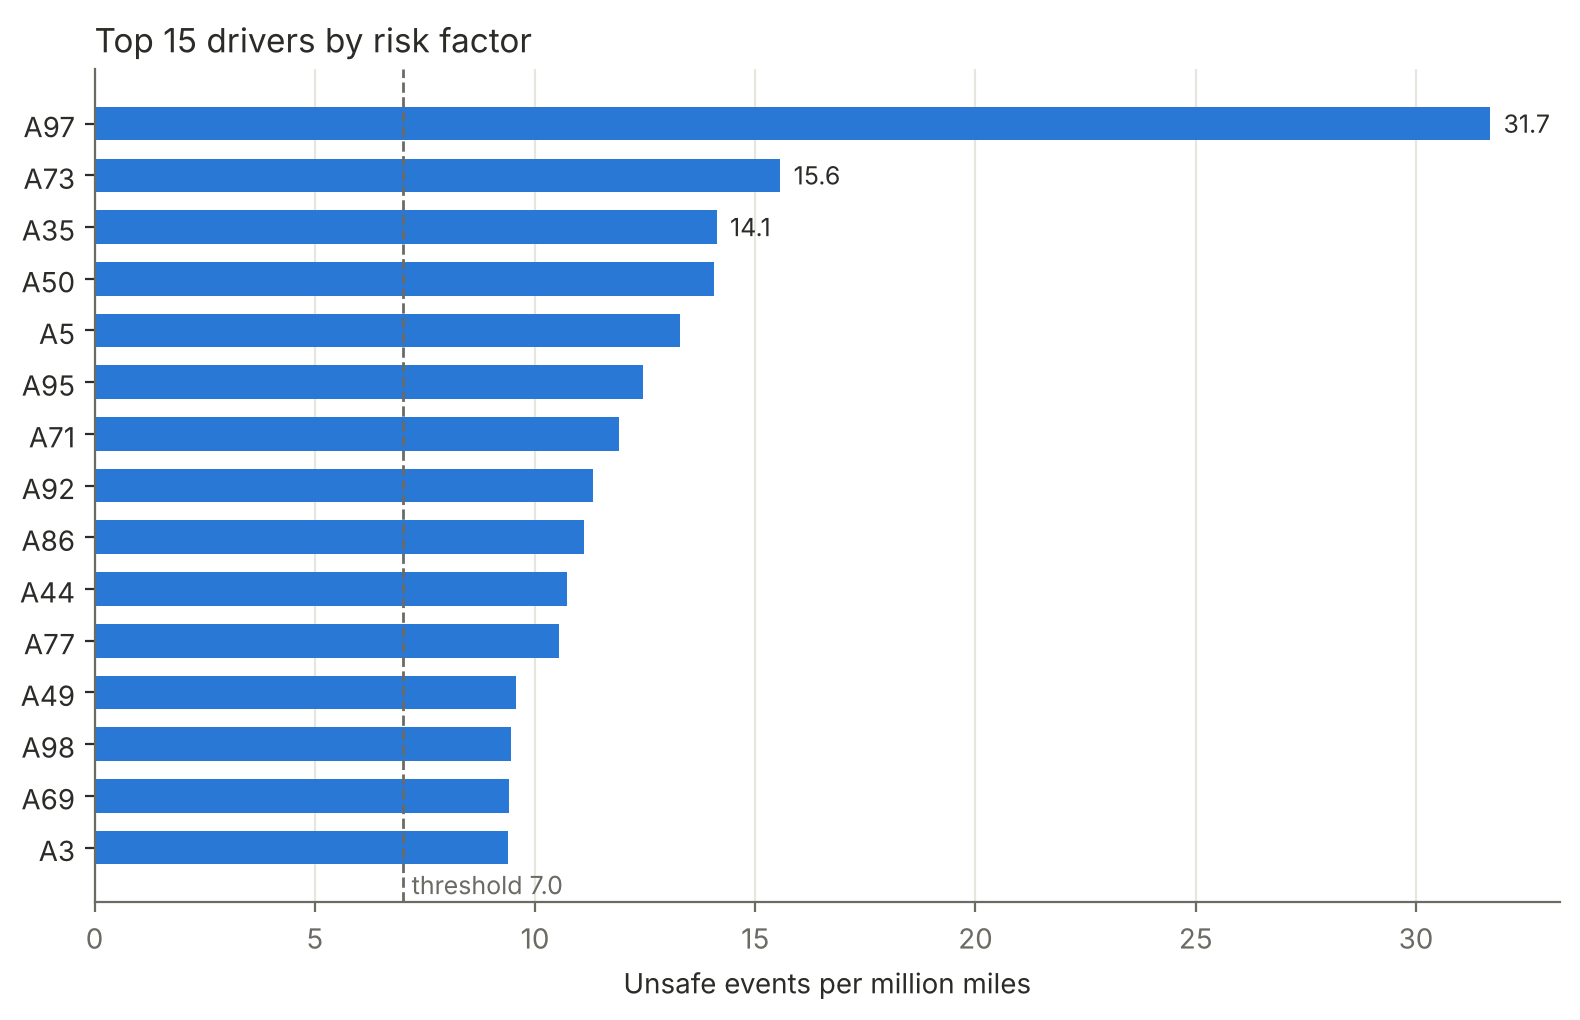

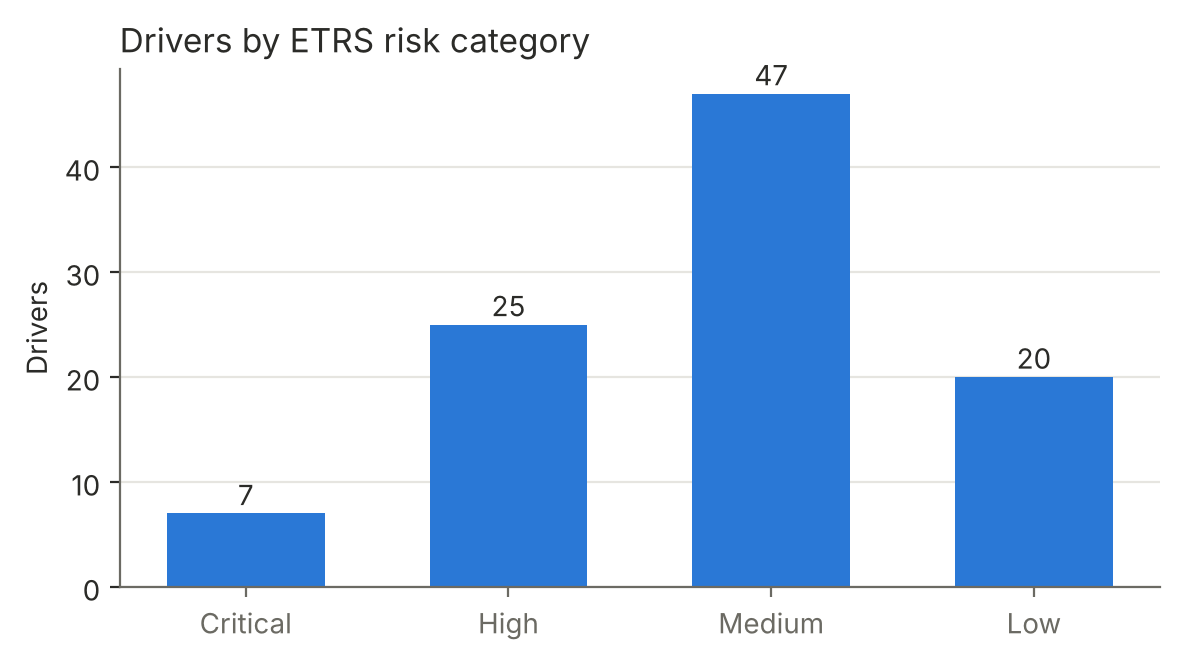

In [11]:
BLUE, INK, MUTED = '#2a78d6', '#2b2b28', '#6b6a63'
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK,
                     'xtick.color': MUTED, 'ytick.color': INK})

top = riskfactor.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(top.driverid, top.riskfactor, color=BLUE, height=0.65)
ax.axvline(7, color=MUTED, lw=1, ls='--')
ax.text(7.2, -0.9, 'threshold 7.0', color=MUTED, fontsize=9)
for y, v in list(enumerate(top.riskfactor))[-3:]:
    ax.text(v + 0.3, y, f'{v:.1f}', va='center', color=INK, fontsize=9)
ax.set_xlabel('Unsafe events per million miles')
ax.set_title('Top 15 drivers by risk factor', loc='left', color=INK, fontsize=12)
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='x', color='#e6e5e0', lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig('../analysis/top15_riskfactor.png', dpi=150); plt.show()

counts = d.risk_category.value_counts().reindex(order, fill_value=0)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(counts.index, counts.values, color=BLUE, width=0.6)
for x, v in enumerate(counts.values):
    ax.text(x, v + 0.8, str(v), ha='center', color=INK)
ax.set_ylabel('Drivers'); ax.set_title('Drivers by ETRS risk category', loc='left', color=INK, fontsize=12)
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', color='#e6e5e0', lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig('../analysis/risk_categories.png', dpi=150); plt.show()

In [12]:
# export result tables
riskfactor.round(4).to_csv('../analysis/riskfactor_corrected.csv', index=False)
d.sort_values('etrs', ascending=False).round(4).to_csv('../analysis/advanced_risk_category_corrected.csv', index=False)
corr.to_csv('../analysis/correlation_matrix.csv')